# S Shape Functions Theory

> **About this Python edition, version 1.0.0 (16 November 2026).** A port of the Wolfram notebook [`S-Shape-Functions-Theory.nb`](S-Shape-Functions-Theory.nb) (PDF: [`S-Shape-Functions-Theory.pdf`](S-Shape-Functions-Theory.pdf)) to Python 3.14 with NumPy, SciPy, SymPy, Matplotlib, NetworkX and ipywidgets. The text, the numbering of sections, equations, figures, tables and theorems, and the cell indices (c.N) are the same as in the Wolfram notebook. Symbolic checks use SymPy; all tables and figures are computed by the cells. Figure 2 is interactive when the notebook runs in JupyterLab and also shown as a static plot.

*Sigmoidal functions, Cybenko's universal approximation theorem, and Kolmogorov's superposition theorem*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="28">  
Advanced AI System Programming  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  
Computational Classnotes · revision 7  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## Abstract

S-shaped (sigmoidal) functions rise from 0 to 1 around a threshold. This notebook follows them from biology to the mathematics of neural networks. Section 0 shows six well-documented biological examples, from the voltage gating of ion channels and the oxygen binding of hemoglobin to a genetic switch in the fruit-fly embryo, diffusion fronts, logistic population growth and the contrast response of visual neurons, and shows that each is the logistic function of a scaled and shifted input. Sections 1 and 2 define sigmoidal functions and explain why they became the activation of artificial neurons. Section 3 states and sketches the proof of Cybenko's universal approximation theorem (1989): finite sums of one fixed continuous sigmoid, applied to affine functions of the input, approximate every continuous function on the unit cube. It also explains, in everyday and in mathematical terms, how such a one-hidden-layer network computes and how its gradient flows along the arrows of its diagram. Sections 4 and 5 make the theorem concrete with staircase constructions in one dimension and least-squares fits in two, and relate the rate of convergence to the modulus of continuity. Sections 6 and 7 connect the result to Kolmogorov's superposition theorem (1957), which answers Hilbert's 13th problem by representing every continuous function exactly with one-variable functions and addition. They compare the two theorems and the debate over their relevance, and survey later results: Hornik, Stinchcombe and White, Hornik, Leshno, Lin, Pinkus and Schocken, Barron, and Kolmogorov–Arnold networks. Appendix A collects the definition, examples and counterexamples of continuity. All formulas are checked in Python (SymPy and NumPy) and every figure is reproducible from the numbered code cells.

**Keywords:** sigmoidal function; logistic function; universal approximation theorem; Cybenko; Kolmogorov–Arnold superposition theorem; Hilbert's 13th problem; neural networks; Hill equation; Boltzmann gating; logistic growth; modulus of continuity; Python

Every code cell starts with a comment such as `# c.7` giving its index, so a cell can be referred to by number. Each notebook runs in its own Python kernel, so definitions from other notebooks cannot interfere with it; Kernel → Restart Kernel and Run All Cells gives a clean run from the top.

Libraries and settings for all figures and tables. Run this cell first. figFont and tabFont set the font sizes of every figure and every table; wFull and wHalf keep every figure inside an A4 page when the notebook is printed or saved as PDF.

**Wolfram notebook**: 
https://www.wolframcloud.com/obj/ccn2/Published/S_Shape_Functions_Theory.nb

**CCN Node**: 
https://discuss.compclassnotes.com/t/s-shape-functions-theory/522

**CCN Wiki**: 
https://wiki.compclassnotes.com/books/neural-networks/page/s-shape-functions-theory (.md)

In [1]:
# c.0
import io
import pathlib
import urllib.parse

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx
from scipy.special import expit, erf, erfc
from IPython.display import display, HTML

figFont = 14      # font size in figures and diagrams
tabFont = 10      # font size in tables
wFull = 440 / 72  # full figure width in inches (440 pt); A4 text width is ~487 pt
wHalf = 215 / 72  # width of each panel in a two-column figure (215 pt)
plt.rcParams.update({
    "font.size": figFont, "axes.titlesize": figFont, "axes.labelsize": figFont,
    "legend.fontsize": figFont, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False})

def logistic_sigmoid(t):
    """LogisticSigmoid: 1/(1 + e^(-t)), without overflow warnings."""
    return expit(t)

def unit_step(t):
    """UnitStep: 0 for t < 0 and 1 for t >= 0."""
    return np.heaviside(t, 1.0)

def legend_below(ax, ncol=4, **kw):
    """Legend under the plot, like Placed[LineLegend[...], Below]."""
    kw.setdefault("bbox_to_anchor", (0.5, -0.2))
    ax.legend(loc="upper center", ncol=ncol, **kw)

def table(rows, label):
    """A framed table with a grey header row and a bold label on top."""
    cell = f"border:1px solid #999;padding:3px 8px;text-align:left;font-size:{tabFont}pt"
    html = [f"<p style='font-weight:bold;font-size:{tabFont + 1}pt;margin-bottom:2px'>{label}</p>",
            "<table style='border-collapse:collapse'>"]
    for i, row in enumerate(rows):
        bg = "background:#ebebeb;" if i == 0 else ""
        html.append("<tr>" + "".join(f"<td style='{bg}{cell}'>{v}</td>" for v in row) + "</tr>")
    display(HTML("".join(html) + "</table>"))

# small photo from Wikimedia Commons; needs internet, else uses the copy in photos/
commonsURL = "https://commons.wikimedia.org/wiki/Special:FilePath/"

def commonsImage(file, local=None, w=160):
    from PIL import Image
    img = None
    try:
        import requests
        r = requests.get(commonsURL + urllib.parse.quote(file) + "?width=400", timeout=10,
                         headers={"User-Agent": "ComputationalClassnotes/1.0"})
        r.raise_for_status()
        img = Image.open(io.BytesIO(r.content))
    except Exception:
        if local and pathlib.Path(local).exists():
            img = Image.open(local)
    if img is None:
        print("(photo not available offline)")
        return
    img = img.convert("RGB")
    img.thumbnail((w, 10 * w))
    display(img)

## Index of theorems, equations, figures, tables and code cells

### Theorems

- Theorem 1.  Cybenko: continuous discriminatory σ gives density in C(${I}_{n}$) (section 3)
- Lemma 1.  Cybenko: bounded measurable sigmoidals are discriminatory (section 3)
- Theorem 2.  Cybenko: the universal approximation theorem (section 3)
- Theorem 3.  Cybenko: decision regions (section 3)
- Theorem 4.  Cybenko: L¹ approximation (section 3)
- Theorem 5.  Kolmogorov: the superposition theorem (section 6)
- Theorem 6.  Hornik, Stinchcombe and White: squashing functions (section 7)
- Theorem 7.  Hornik: bounded nonconstant activations (section 7)
- Theorem 8.  Leshno, Lin, Pinkus and Schocken: non-polynomial activations (section 7)
- Theorem 9.  Heine–Cantor (Appendix A)
- Theorem 10. Extreme value theorem (Appendix A)

### Equations

- (0.1)–(0.6)  Boltzmann gating, Hill binding, gene switch, diffusion front, logistic growth, Naka–Rushton (section 0)
- (1)  Definition of a sigmoidal function: its two limits (section 1)
- (2)  The logistic function, its derivative, and its link to tanh (section 2)
- (3)  Cybenko's sum G(x): a one-hidden-layer network (section 3)
- (4)  The network of Figure 3, node by node and in matrix form (section 3)
- (5)  The gradient as a sum over the paths of Figure 3 (section 3)
- (6)  Definition of a discriminatory function (section 3)
- (7)  The staircase ${G}_{N}$ built from steep sigmoids (section 4)
- (8)  Kolmogorov's superposition formula (section 6)
- (9)  Cybenko's sum and Kolmogorov's formula side by side (section 7)
- (10) Continuity at a point, the ε–δ definition (Appendix A)
- (11) Uniform continuity (Appendix A)
- (12) Modulus of continuity (Appendix A)

### Figures

- Figure 0.1–0.6.  Voltage gating, oxygen binding, hunchback, diffusion, Paramecium growth, visual neuron (section 0, c.0.1–c.0.6)
- Figure 1.  A gallery of S-shaped functions (section 1, c.3)
- Figure 2.  A steep sigmoid approaching the step, interactive (section 2, c.5)
- Figure 3.  Cybenko's network with one hidden layer, weights on the arrows (section 3, c.6)
- Figure 4.  Example A: a staircase of 10 sigmoids following a smooth function (section 4, c.8)
- Figure 5.  Examples B–E: kink, steep root, narrow bump, jump (section 4, c.10)
- Figure 6.  The 2D target function g(x, y) (section 5, c.12)
- Figure 7.  The fit by 100 sigmoids and its error (section 5, c.15)
- Figure 8.  Kolmogorov's formula drawn as a network, n = 2 (section 6, c.17)
- Figure 9.  Continuous functions, including some strange ones (Appendix A, c.21)
- Figure 10. Functions that are not continuous, or not uniformly continuous (Appendix A, c.22)

### Tables

- Photo 0.1, 0.2, 0.3, 0.5, 0.6.  Squid, hemoglobin, fruit fly, Paramecium, cat (section 0, c.0.1i–c.0.6i)
- Table 0.1.  Six biological S-curves as σ(slope × (input - threshold)) (section 0)
- Table 1.  Limits of the gallery functions (section 1, c.2)
- Table 2.  Staircase error against N for example A (section 4, c.9)
- Table 3.  Staircase error against N for examples A–E (section 4, c.11)
- Table 4.  Least-squares fit error against N (section 5, c.14)
- Table 5.  Kolmogorov and Cybenko compared (section 7)
- Table 6.  Modulus of continuity of the section 4 examples (Appendix A, c.18)
- Table 7.  Examples and counterexamples summarized (Appendix A)

## 0. S functions in living organisms

Long before artificial neurons, nature was full of S-shaped responses. A cell, a protein or a population often reacts weakly to a small stimulus, strongly over a narrow middle range, and then saturates. This section collects six well-documented examples. Each one, written in the right variable, is exactly the logistic function σ(t) = 1/(1 + ${e}^{-t}$) of section 2, applied to a scaled and shifted input, σ(slope × (input - threshold)). That is the same building block as one hidden unit σ(y x + θ) in Cybenko's network, Eq. (3): the threshold plays the role of θ and the slope the role of y.

The equations of this section are tagged (0.1)–(0.6), its figures Figure 0.1–0.6, its photos Photo 0.1–0.6, its references [0.1]–[0.15] and its code cells c.0.1–c.0.6 (photo cells c.0.1i–c.0.6i), so the numbering of the rest of the notebook is unchanged. Run c.0 first.

### 0.1 Voltage gating of ion channels

Voltage-gated ion channels open and close as the membrane voltage changes, because charged parts of the protein (the voltage sensor) move in the membrane's electric field. Their open probability rises in an S-shape with voltage, and it is usually fitted with a two-state Boltzmann function [0.2, 0.3], characterized by a half-activation voltage ${V}_{1/2}$ and a slope set by the gating charge z. The same Boltzmann form is mathematically analogous to the Hill equation of 0.2.

*Photo 0.1. A squid of the genus Loligo (here the common squid, L. vulgaris). Hodgkin and Huxley measured the S-shaped gating of sodium and potassium channels on the giant axon of Loligo. Hans Hillewaert, CC BY-SA 4.0, Wikimedia Commons.*

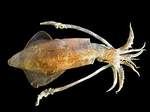

In [2]:
# c.0.1i
commonsImage("Loligo_vulgaris.jpg", "photos/squid-loligo-vulgaris.jpg")

$$
{P}_{\text{open}} ( V ) = \frac{1}{1 + {e}^{- \frac{z \  F ( V - {V}_{1/2} )}{R \  T}}} = \sigma ( \frac{V - {V}_{1/2}}{k} ) , \quad  k = \frac{R \  T}{z \  F} \quad  \tag{0.1}
$$

At body temperature RT/F is about 26.7 mV, so a channel that moves z = 4 elementary charges has a slope k of about 6.7 mV: a change of a few millivolts switches it from mostly closed to mostly open. Figure 0.1 uses an illustrative ${V}_{1/2}$ = -30 mV.

*Figure 0.1. Open probability of a voltage-gated channel, Eq. (0.1), for gating charges z = 1, 2, 4 and 6. More charge gives a steeper switch.*

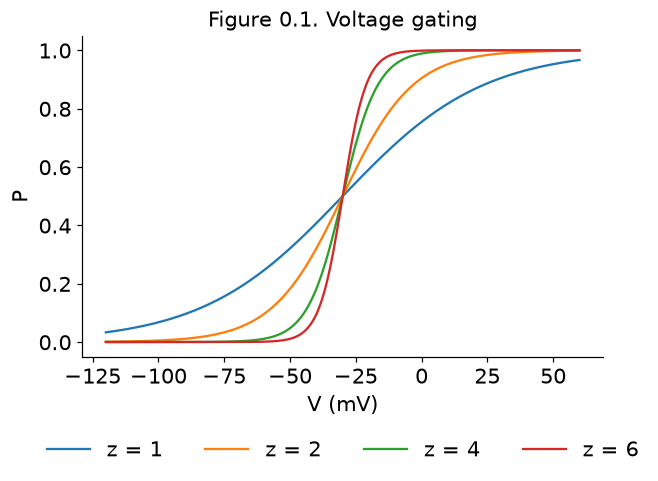

In [3]:
# c.0.1
rtf = 26.7   # RT/F at 37 °C, in mV
def pOpen(v, vHalf, z):
    return logistic_sigmoid(z * (v - vHalf) / rtf)

v = np.linspace(-120, 60, 600)
fig, ax = plt.subplots(figsize=(wFull, 0.62 * wFull))
for z in [1, 2, 4, 6]:
    ax.plot(v, pOpen(v, -30, z), label=f"z = {z}")
ax.set(xlabel="V (mV)", ylabel="P", title="Figure 0.1. Voltage gating")
legend_below(ax)
plt.show()

The Hodgkin–Huxley model of the nerve impulse (1952), measured on the giant axon of the squid Loligo, is built from exactly such voltage-dependent S-curves for its sodium and potassium gates [0.1]. In their data the sodium conductance changed e-fold for every 4 mV, and the potassium conductance for every 5–6 mV. The action potential itself is what you get when many of these switches act together.

### 0.2 Oxygen saturation of hemoglobin

Hemoglobin binds oxygen cooperatively: once one of its four sites holds O₂, the others bind more easily. The result is the S-shaped oxygen dissociation curve, described since 1910 by the Hill equation [0.4]. For normal human blood the Hill exponent n = 2.7 fits well over most of the range [0.5], with half-saturation pressure ${P}_{50}$ of about 26.8 mmHg. Myoglobin, a single-site protein, binds without cooperativity and has a hyperbolic curve (n = 1) with much higher affinity.

*Photo 0.2. Structure of human hemoglobin (PDB 1GZX): four subunits, each with an oxygen-binding heme. Their interaction makes binding cooperative. Richard Wheeler (Zephyris), CC BY-SA 3.0, Wikimedia Commons.*

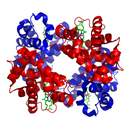

In [4]:
# c.0.2i
commonsImage("1GZX_Haemoglobin.png", "photos/hemoglobin-1gzx.jpg")

$$
S ( P ) = \frac{{( P / {P}_{50} )}^{n}}{1 + {( P / {P}_{50} )}^{n}} = \sigma ( n \  \ln  ( P / {P}_{50} ) ) \quad  \tag{0.2}
$$

The second form shows that the Hill curve is the logistic function of the logarithm of the pressure. On a linear pressure axis it is S-shaped only when n > 1; that is why the shape is the signature of cooperativity. The S-shape is what makes blood work: nearly full in the lungs (about 100 mmHg), yet giving up a quarter of its oxygen in resting tissue (about 40 mmHg).

*Figure 0.2. Oxygen saturation of hemoglobin (n = 2.7, ${P}_{50}$ = 26.8 mmHg) and of myoglobin (n = 1, ${P}_{50}$ = 2.8 mmHg, a typical textbook value). Grid lines mark venous (40 mmHg) and arterial (100 mmHg) pressure.*

Hill form = logistic of log P: True
hemoglobin saturation at 40 and 100 mmHg: [0.747 0.972]


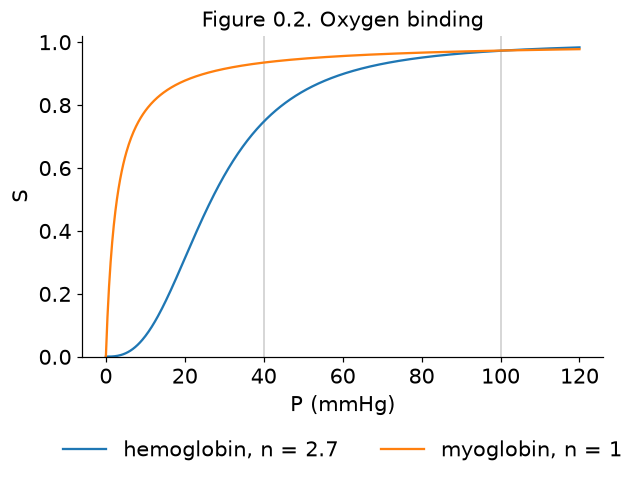

In [5]:
# c.0.2
def hill(p, p50, n):
    return (p / p50)**n / (1 + (p / p50)**n)

p, p50, n = sp.symbols("p p50 n", positive=True)
sigma = lambda z: 1 / (1 + sp.exp(-z))   # LogisticSigmoid in SymPy
print("Hill form = logistic of log P:",
      sp.simplify(hill(p, p50, n) - sigma(n * sp.log(p / p50))) == 0)
print("hemoglobin saturation at 40 and 100 mmHg:",
      np.round([hill(40., 26.8, 2.7), hill(100., 26.8, 2.7)], 3))
pp = np.linspace(0, 120, 600)
fig, ax = plt.subplots(figsize=(wFull, 0.62 * wFull))
ax.plot(pp, hill(pp, 26.8, 2.7), label="hemoglobin, n = 2.7")
ax.plot(pp, hill(pp, 2.8, 1), label="myoglobin, n = 1")
for g in (40, 100):
    ax.axvline(g, color="0.8", lw=1, zorder=0)
ax.set(ylim=(0, 1.02), xlabel="P (mmHg)", ylabel="S", title="Figure 0.2. Oxygen binding")
legend_below(ax, ncol=2)
plt.show()

In a test run the saturation was 0.75 at 40 mmHg and 0.97 at 100 mmHg.

### 0.3 A genetic switch: hunchback in the fruit-fly embryo

In the early Drosophila embryo the Bicoid protein forms a smooth, roughly exponential gradient from head to tail. The gene hunchback reads this gradient and switches from strongly on to off across a sharp boundary at mid-embryo. Fits of hunchback expression against Bicoid concentration give Hill coefficients of about 5, with reported values between about 4 and 10 depending on the method and the stage [0.6–0.9].

*Photo 0.3. The fruit fly Drosophila melanogaster, about 2.5 mm long. André Karwath (Aka), CC BY-SA 2.5, Wikimedia Commons.*

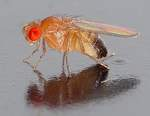

In [6]:
# c.0.3i
commonsImage("Drosophila_melanogaster_-_side_(aka).jpg", "photos/drosophila-melanogaster.jpg")

$$
B ( x ) = {B}_{A} {e}^{- x / \lambda} , \quad  \text{hb} ( x ) = \frac{{B}^{H}}{{B}^{H} + {B}_{0}^{H}} = \sigma ( - \frac{H}{\lambda} ( x - {x}_{0} ) ) \quad  \tag{0.3}
$$

An exponential gradient fed into a Hill function gives exactly a logistic function of position, centred at ${x}_{0}$ = λ ln(${B}_{A}$/${B}_{0}$) with width λ/H. A larger Hill coefficient H gives a sharper boundary. Figure 0.3 uses a decay length λ of a fifth of the embryo length, of the order of the 120 μm used in one recent model [0.10], and places the boundary at mid-embryo.

*Figure 0.3. The Bicoid gradient (dashed) and the hunchback response of Eq. (0.3) for H = 1, 3 and 5. Position is measured as a fraction of the embryo length, from head (0) to tail (1).*

Hill of exponential = logistic: True


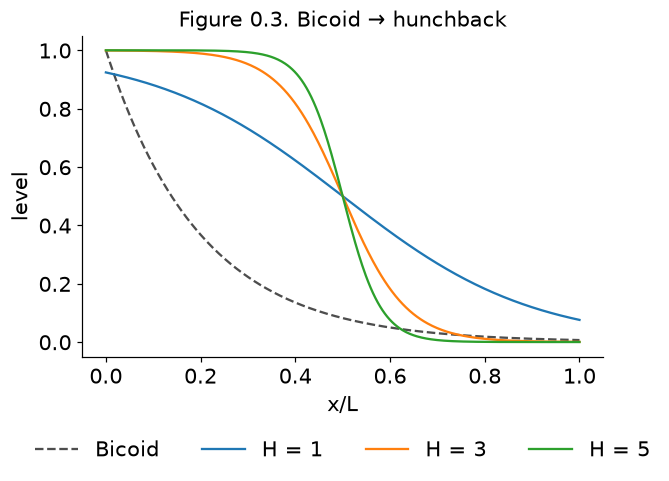

In [7]:
# c.0.3
b, b0, l, h = sp.symbols("b b0 l h", positive=True)
x = sp.symbols("x", real=True)
diff03 = ((b * sp.exp(-x / l))**h / ((b * sp.exp(-x / l))**h + b0**h)
          - sigma(-(h / l) * (x - l * sp.log(b / b0))))
diff03 = sp.powsimp(sp.expand_log(sp.expand_power_base(diff03, force=True), force=True), force=True)
print("Hill of exponential = logistic:", sp.simplify(diff03) == 0)
# decay length and boundary, as fractions of the embryo length
lam_b, x0 = 0.2, 0.5
def hb(x, h):
    return logistic_sigmoid(-(h / lam_b) * (x - x0))

xs = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(wFull, 0.62 * wFull))
ax.plot(xs, np.exp(-xs / lam_b), "--", color="0.3", label="Bicoid")
for H in [1, 3, 5]:
    ax.plot(xs, hb(xs, H), label=f"H = {H}")
ax.set(xlabel="x/L", ylabel="level", title="Figure 0.3. Bicoid → hunchback")
legend_below(ax)
plt.show()

Biologists describe such a gene as a switch with a dimmer that suddenly snaps on. In the language of this notebook it is one S-shaped unit reading a graded input.

### 0.4 Diffusion fronts and diffusion saturation

Diffusion produces S-shapes in both space and time. Suppose a substance at concentration ${C}_{0}$ fills the region x < 0 and is absent from x > 0, for example a signalling molecule at the edge of a tissue. Solving Fick's second law gives an error-function front [0.11]:

$$
C ( x , t ) = \frac{{C}_{0}}{2} \  \mathrm{erfc}  ( \frac{x}{2 \sqrt{D \  t}} ) = {C}_{0} \  {\sigma}_{\mathrm{erf}} ( - \frac{x}{2 \sqrt{D \  t}} ) \quad  \tag{0.4}
$$

Here ${\sigma}_{\mathrm{erf}}$(s) = (1 + erf s)/2 is the error-function sigmoid of Figure 1. The front has width of the order of the diffusion length 2√(D t), which grows only like the square root of time. With a constant source at the boundary of a half-space, the profile is the complementary error function itself.

Seen from a fixed point x > 0, the concentration starts flat, rises, and saturates towards ${C}_{0}$/2: an S-shaped curve in time, which is clearest on a logarithmic time axis. This is diffusion saturation. A related case is uptake through carriers in a cell membrane, which saturates hyperbolically with concentration (Michaelis–Menten kinetics) and looks S-shaped on a logarithmic concentration axis.

*Figure 0.4. (a) Concentration profiles of Eq. (0.4) after 0.1 s, 1 s and 10 s, with x in μm. (b) Concentration at x = 100 μm against time on a logarithmic axis. D = 1000 μm²/s (${10}^{-9}$ m²/s), of the order of a small molecule in water.*

Eq. (0.4), erfc = reflected erf sigmoid: True


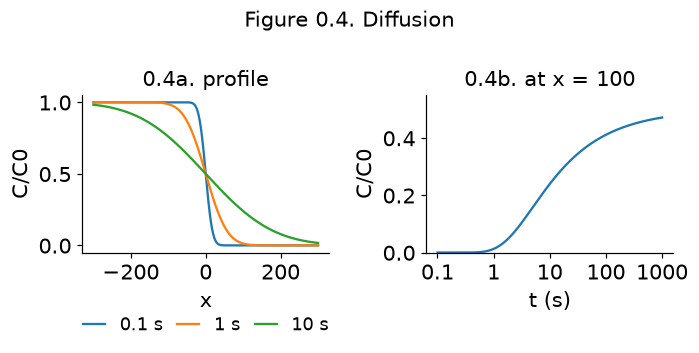

In [8]:
# c.0.4
dC = 1000.   # diffusion coefficient in μm^2/s
def cdiff(x, t):
    return erfc(x / (2 * np.sqrt(dC * t))) / 2

s = sp.symbols("s", real=True)
print("Eq. (0.4), erfc = reflected erf sigmoid:",
      sp.simplify((sp.erfc(s) / 2 - (1 - (1 + sp.erf(s)) / 2)).rewrite(sp.erf)) == 0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(2 * wHalf + 0.6, 1.25 * wHalf))
xx = np.linspace(-300, 300, 600)
for t in [0.1, 1, 10]:
    a1.plot(xx, cdiff(xx, t), label=f"{t:g} s")
a1.set(xticks=[-200, 0, 200], xlabel="x", ylabel="C/C0", title="0.4a. profile")
legend_below(a1, ncol=3, fontsize=figFont - 2, handlelength=1.2, columnspacing=0.8,
             bbox_to_anchor=(0.5, -0.3))
tt = np.logspace(-1, 3, 400)
a2.semilogx(tt, cdiff(100, tt))
a2.set(ylim=(0, 0.55), xticks=[0.1, 1, 10, 100, 1000], xticklabels=["0.1", "1", "10", "100", "1000"],
       xlabel="t (s)", ylabel="C/C0", title="0.4b. at x = 100")
fig.suptitle("Figure 0.4. Diffusion", fontsize=figFont)
fig.tight_layout()
plt.show()

### 0.5 Population growth

A population with plenty of food grows exponentially, then slows as resources run short, and levels off at the carrying capacity K. Verhulst introduced a model for this in 1838 and in 1845 named its solution the logistic curve [0.12]. G. F. Gause's Paramecium experiments of the 1930s are the classic test: each species grown alone showed logistic growth to a stable carrying capacity [0.13].

*Photo 0.5. Paramecium aurelia under the optical microscope, the species of Figure 0.5. Barfooz, CC BY-SA 3.0, Wikimedia Commons.*

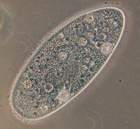

In [9]:
# c.0.5i
commonsImage("Paramecium.jpg", "photos/paramecium-aurelia.jpg")

$$
\frac{d N}{d t} = r \  N ( 1 - \frac{N}{K} ) \quad  \implies \quad  N ( t ) = K \  \sigma ( r ( t - {t}_{1/2} ) ) , \quad  {t}_{1/2} = \frac{\ln  ( ( K - {N}_{0} ) / {N}_{0} )}{r} \quad  \tag{0.5}
$$

Figure 0.5 uses values fitted to Gause's data for Paramecium aurelia grown alone: ${N}_{0}$ = 0.6, r = 0.8 per day and K = 230, with population measured as a standardized volume [0.13].

*Figure 0.5. Logistic growth of Paramecium aurelia, Eq. (0.5). The dashed line is the carrying capacity K.*

Eq. (0.5), logistic form: True


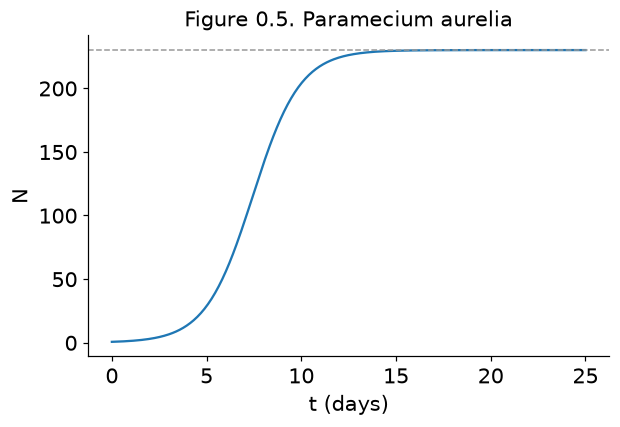

In [10]:
# c.0.5
def logistic(t, n0, r, k):
    return k / (1 + (k - n0) / n0 * np.exp(-r * t))

t, n0, r, k = sp.symbols("t n0 r k", positive=True)
lg = k / (1 + (k - n0) / n0 * sp.exp(-r * t))
print("Eq. (0.5), logistic form:",
      sp.simplify(lg - k * sigma(r * (t - sp.log((k - n0) / n0) / r))) == 0)
td = np.linspace(0, 25, 400)
fig, ax = plt.subplots(figsize=(wFull, 0.62 * wFull))
ax.plot(td, logistic(td, 0.6, 0.8, 230))
ax.axhline(230, ls="--", color="0.6", lw=1)
ax.set(xlabel="t (days)", ylabel="N", title="Figure 0.5. Paramecium aurelia")
plt.show()

### 0.6 The response of a real neuron

Neurons in the visual cortex fire faster as the contrast of a stimulus increases, but not linearly: the response grows slowly at low contrast, steeply in the middle, and saturates at high contrast. This contrast-response function has a sigmoidal shape and is usually fitted with the Naka–Rushton (hyperbolic ratio) equation, first used for retinal data from fish in 1966 [0.14, 0.15]. Plotted against the logarithm of contrast, it is an S-curve.

*Photo 0.6. A domestic cat. Albrecht and Hamilton measured contrast-response functions in the visual cortex of cat and monkey [0.15]. Alvesgaspar, CC BY-SA 3.0, Wikimedia Commons.*

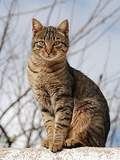

In [11]:
# c.0.6i
commonsImage("Cat_November_2010-1a.jpg", "photos/cat.jpg")

$$
R ( c ) = {R}_{\max } \frac{{c}^{n}}{{c}^{n} + {c}_{50}^{n}} = {R}_{\max } \  \sigma ( n \  \ln  ( c / {c}_{50} ) ) \quad  \tag{0.6}
$$

This is the Hill equation (0.2) again, in a new place: biology reuses the same S-shape for very different mechanisms. It is also the closest biological relative of the artificial neuron of section 3: an input, a threshold ${c}_{50}$, a slope n, and a saturating output. Figure 0.6 uses the illustrative values n = 2 and ${c}_{50}$ = 0.2.

*Figure 0.6. Contrast response of a model visual neuron, Eq. (0.6), against log contrast, for n = 1, 2 and 4.*

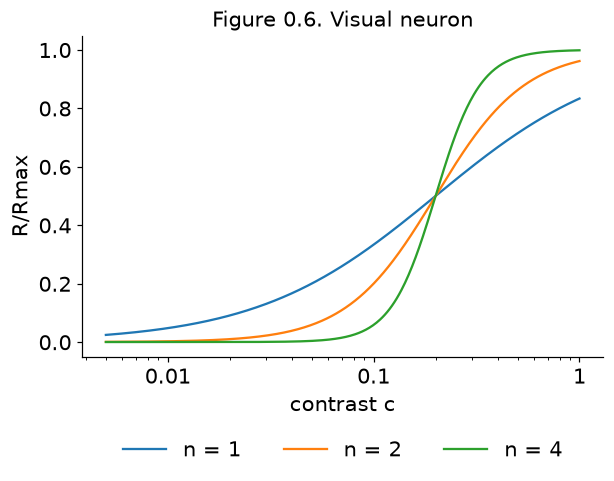

In [12]:
# c.0.6
def naka(c, n, c50):
    return c**n / (c**n + c50**n)

cc = np.logspace(np.log10(0.005), 0, 400)
fig, ax = plt.subplots(figsize=(wFull, 0.62 * wFull))
for nn in [1, 2, 4]:
    ax.semilogx(cc, naka(cc, nn, 0.2), label=f"n = {nn}")
ax.set(xticks=[0.01, 0.1, 1], xticklabels=["0.01", "0.1", "1"],
       xlabel="contrast c", ylabel="R/Rmax", title="Figure 0.6. Visual neuron")
legend_below(ax, ncol=3)
plt.show()

### 0.7 One shape, many mechanisms

*Table 0.1. The six examples written as σ(slope × (input - threshold)).*

| system | input | output | threshold | slope |
|---|---|---|---|---|
| ion channel (0.1) | voltage V | open probability | V<sub>1/2</sub> | zF/(RT) |
| hemoglobin (0.2) | ln P | O<sub>2</sub> saturation | P<sub>50</sub> = 26.8 mmHg | n = 2.7 |
| hunchback gene (0.3) | position x | expression | x<sub>0</sub> = mid-embryo | H/λ, H = 5 |
| diffusion front (0.4) | position x | concentration | x = 0 | 1/(2√(Dt)) |
| population (0.5) | time t | N/K | t<sub>1/2</sub> | r |
| visual neuron (0.6) | ln c | R/R<sub>max</sub> | c<sub>50</sub> | n |


In every row the threshold sets where the switch happens and the slope sets how sharp it is: these are θ and y of one unit of Eq. (3). Living systems build complex behaviour by combining many such switches, many channels in one membrane, many genes in one network, many neurons in one brain. Sections 3 and 6 ask the mathematical version of that question: what can sums of S-shaped units represent?

### 0.8 References for section 0

- [0.1] A. L. Hodgkin, A. F. Huxley, A quantitative description of membrane current and its application to conduction and excitation in nerve, J. Physiol. 117 (1952) 500–544. doi:10.1113/jphysiol.1952.sp004764
- [0.2] S. Chowdhury, B. Chanda, Estimating the voltage-dependent free energy change of ion channels using the median voltage for activation, J. Gen. Physiol. 139 (2012) 3–17. doi:10.1085/jgp.201110722
- [0.3] F. Bezanilla, C. A. Villalba-Galea, The gating charge should not be estimated by fitting a two-state model to a Q-V curve, J. Gen. Physiol. 142 (2013) 575–578. doi:10.1085/jgp.201311056
- [0.4] A. V. Hill, The possible effects of the aggregation of the molecules of haemoglobin on its dissociation curves, J. Physiol. 40 (1910) iv–vii.
- [0.5] R. K. Dash, J. B. Bassingthwaighte, Blood HbO2 and HbCO2 dissociation curves at varied O2, CO2, pH, 2,3-DPG and temperature levels, Ann. Biomed. Eng. 38 (2010). doi:10.1007/s10439-010-9948-y
- [0.6] T. Gregor, D. W. Tank, E. F. Wieschaus, W. Bialek, Probing the limits to positional information, Cell 130 (2007) 153–164.
- [0.7] F. J. P. Lopes, F. M. C. Vieira, D. M. Holloway, P. M. Bisch, A. V. Spirov, Spatial bistability generates hunchback expression sharpness in the Drosophila embryo, PLoS Comput. Biol. 4 (2008) e1000184. doi:10.1371/journal.pcbi.1000184
- [0.8] F. J. P. Lopes, A. V. Spirov, P. M. Bisch, The role of Bicoid cooperative binding in the patterning of sharp borders in Drosophila melanogaster, Dev. Biol. 370 (2012) 165–172. doi:10.1016/j.ydbio.2012.07.020
- [0.9] J. Park et al., Dissecting the sharp response of a canonical developmental enhancer reveals multiple sources of cooperativity, eLife 8 (2019) e41266. doi:10.7554/eLife.41266
- [0.10] M. Vennettilli, K. P. Ramachandran, A. Mugler, Near-critical gene expression in embryonic boundary precision, arXiv:2505.11212 (2025).
- [0.11] H. Mehrer, Diffusion in Solids, Springer (2007), chapter 3, Solutions of the diffusion equation. doi:10.1007/978-3-540-71488-0_3
- [0.12] P.-F. Verhulst, Notice sur la loi que la population suit dans son accroissement, Correspondance mathématique et physique 10 (1838) 113–121.
- [0.13] G. F. Gause, The Struggle for Existence, Williams & Wilkins (1934). Data and the fit used here: L. K. Mühlbauer, M. Schulze, A. T. Clark, R package gauseR.
- [0.14] K. I. Naka, W. A. H. Rushton, S-potentials from luminosity units in the retina of fish (Cyprinidae), J. Physiol. 185 (1966) 587–599. doi:10.1113/jphysiol.1966.sp008003
- [0.15] D. G. Albrecht, D. B. Hamilton, Striate cortex of monkey and cat: contrast response function, J. Neurophysiol. 48 (1982) 217–237.

Photo credits. Photos 0.1–0.6 come from Wikimedia Commons and are loaded when their cells run; without an internet connection the cells show the small copies in `photos/`. Each photo keeps its own licence (CC BY-SA, version as stated in its caption), which is separate from the CC BY-NC-SA 4.0 licence of this notebook.

## 1. What is an S-shaped function?

Cybenko (1989) calls a function σ: ℝ → ℝ sigmoidal if it goes to 0 on the far left and to 1 on the far right:

$$
\lim _{t \to - \infty} \sigma ( t ) = 0 , \quad  \lim _{t \to + \infty} \sigma ( t ) = 1 \tag{1}
$$

Equation (1) is the whole definition. It does not ask for monotonicity, smoothness or even continuity (Appendix A). Continuity is needed only for the main theorem in section 3, and boundedness plus measurability for some of its variants.

A gallery of S-shapes, each rescaled where necessary so that its limits are 0 and 1:

In [13]:
# c.1
def gudermannian(t):
    return 2 * np.arctan(np.tanh(t / 2))

sig = {
    "logistic": logistic_sigmoid,
    "(1 + tanh)/2": lambda t: (1 + np.tanh(t)) / 2,
    "1/2 + arctan/π": lambda t: 1 / 2 + np.arctan(t) / np.pi,
    "(1 + erf)/2": lambda t: (1 + erf(t)) / 2,
    "algebraic": lambda t: (1 + t / np.sqrt(1 + t**2)) / 2,
    "Gudermannian": lambda t: 1 / 2 + gudermannian(t) / np.pi,
    "Heaviside step": unit_step}
# the same functions in SymPy, for exact limits
T = sp.symbols("t", real=True)
sigSym = {
    "logistic": sigma(T),
    "(1 + tanh)/2": (1 + sp.tanh(T)) / 2,
    "1/2 + arctan/π": sp.Rational(1, 2) + sp.atan(T) / sp.pi,
    "(1 + erf)/2": (1 + sp.erf(T)) / 2,
    "algebraic": (1 + T / sp.sqrt(1 + T**2)) / 2,
    "Gudermannian": sp.Rational(1, 2) + 2 * sp.atan(sp.tanh(T / 2)) / sp.pi,
    "Heaviside step": sp.Heaviside(T)}

*Table 1. Each function satisfies both limits of Eq. (1), checked symbolically.*

In [14]:
# c.2
table([["function", "t → -∞", "t → +∞"]] +
      [[k, sp.limit(e, T, -sp.oo), sp.limit(e, T, sp.oo)] for k, e in sigSym.items()],
      "Table 1")

function,t → -∞,t → +∞
logistic,0,1
(1 + tanh)/2,0,1
1/2 + arctan/π,0,1
(1 + erf)/2,0,1
algebraic,0,1
Gudermannian,0,1
Heaviside step,0,1


*Figure 1. A gallery of S-shaped functions. All rise from 0 to 1 but at different speeds.*

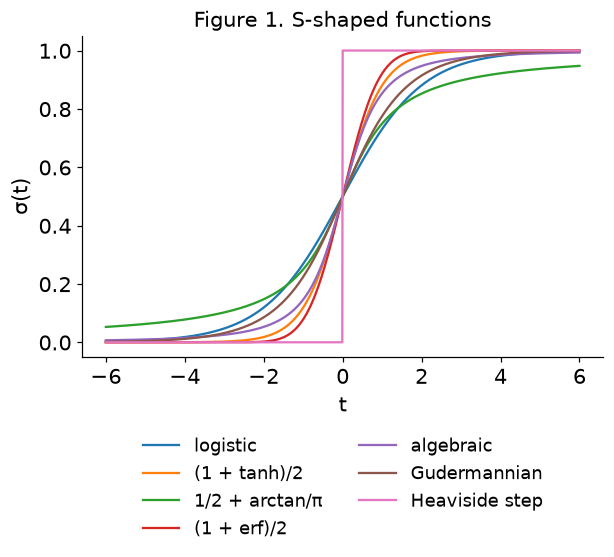

In [15]:
# c.3
tg = np.linspace(-6, 6, 1201)
fig, ax = plt.subplots(figsize=(wFull, 0.62 * wFull))
for k, fn in sig.items():
    ax.plot(tg, fn(tg), label=k)
ax.set(ylim=(-0.05, 1.05), xlabel="t", ylabel="σ(t)", title="Figure 1. S-shaped functions")
legend_below(ax, ncol=2, fontsize=figFont - 2)
plt.show()

The functions differ in how fast they approach their limits: the logistic and tanh forms converge exponentially, while arctan and the algebraic sigmoid creep in like 1/t. For the theory below none of this matters. Only the two limits do.

## 2. Why S-shapes are used in neural networks

- The first model neurons (McCulloch and Pitts, 1943; Rosenblatt's perceptron) fired or did not fire: their activation was the Heaviside step. A step has zero derivative almost everywhere, so you cannot train it by following gradients.
- An S-shaped function is a smooth step. It keeps the on/off behaviour for large inputs but has a useful derivative near the threshold, which is what backpropagation needs.
- It is bounded, so it squashes any input into a fixed range. Hornik, Stinchcombe and White (1989) call such functions squashing functions.
- Its output between 0 and 1 can be read as a probability or a firing rate.
- The logistic function has an especially cheap derivative, expressed through itself:

$$
\sigma ( t ) = \frac{1}{1 + {e}^{- t}} , \quad  {\sigma}^{\prime} ( t ) = \sigma ( t ) ( 1 - \sigma ( t ) ) , \quad  \tanh  \  t = 2 \  \sigma ( 2 t ) - 1 \tag{2}
$$

Both identities of Eq. (2), checked:

In [16]:
# c.4
print(sp.simplify(sp.diff(sigma(T), T) - sigma(T) * (1 - sigma(T))) == 0)
print(sp.simplify(sp.tanh(T).rewrite(sp.exp) - (2 / (1 + sp.exp(-2 * T)) - 1)) == 0)

True
True


So tanh, the default activation of BasicRecurrentLayer (and of PyTorch's `nn.RNN`), is just a rescaled and shifted logistic: everything below applies to it too.

Steepness turns the smooth step back into the hard one. As λ grows, σ(λ t) approaches the Heaviside step, and this limit is the key idea in Cybenko's proof:

*Figure 2. Move the slider: the larger λ, the closer σ(λt) (solid) is to the step (dashed). The slider works only in a running notebook.*

In [17]:
# c.5
from ipywidgets import interact, FloatSlider

tq = np.linspace(-3, 3, 1201)
def figure2(lam=1.0):
    fig, ax = plt.subplots(figsize=(wFull, 0.62 * wFull))
    ax.plot(tq, logistic_sigmoid(lam * tq), lw=2.5, label="σ(λt)")
    ax.plot(tq, unit_step(tq), "--", label="step")
    ax.set(ylim=(-0.05, 1.05), title="Figure 2. Steep sigmoid → step")
    legend_below(ax, ncol=2)
    plt.show()

interact(figure2, lam=FloatSlider(value=1, min=0.2, max=50, step=0.1, description="λ"));

interactive(children=(FloatSlider(value=1.0, description='λ', max=50.0, min=0.2), Output()), _dom_classes=('wi…

*Static version of the interactive Figure 2, for λ = 1, 3, 10, 50:*

<img alt="Figure 2" src="figures/f2.png" width="600">

## 3. Cybenko's theorem (1989)

G. Cybenko, "Approximation by superpositions of a sigmoidal function", Mathematics of Control, Signals, and Systems 2 (1989) 303–314. The question: can finite sums of one fixed S-shaped function, applied to affine combinations of the inputs, approximate every continuous function? Such sums have the form

$$
\begin{gathered}G ( x ) = {\sum}_{j = 1}^{N} {\alpha}_{j} \  \sigma ( {y}_{j}^{\top} x + {\theta}_{j} ) \\ \text{where} \  x \in {I}_{n} = {[ 0 , 1 ]}^{n} , \quad  {y}_{j} \in {\mathbb{R}}^{n} , \quad  {\alpha}_{j} , {\theta}_{j} \in \mathbb{R}\end{gathered} \tag{3}
$$

Eq. (3) is exactly a neural network with one hidden layer of N units: unit j computes σ(${y}_{j}$·x + ${\theta}_{j}$), and the output is a linear combination of the units. Figure 3 draws it for n = 2 inputs and N = 3 hidden units.

*Figure 3. Cybenko's network for n = 2, N = 3. Red labels are the weights carried by the arrows.*

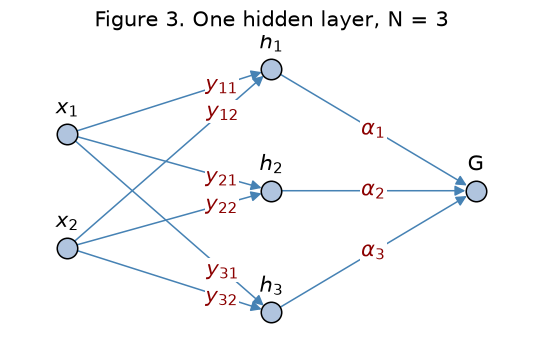

In [18]:
# c.6
nH = 3
G3 = nx.DiGraph()
inE = [(f"x{i}", f"h{j}") for i in (1, 2) for j in range(1, nH + 1)]
outE = [(f"h{j}", "G") for j in range(1, nH + 1)]
G3.add_edges_from(inE + outE)
coords = {"x1": (0, 2.2), "x2": (0, 0.8), "h1": (3, 3), "h2": (3, 1.5), "h3": (3, 0), "G": (6, 1.5)}
names = {"x1": "$x_1$", "x2": "$x_2$", "h1": "$h_1$", "h2": "$h_2$", "h3": "$h_3$", "G": "G"}
fig, ax = plt.subplots(figsize=(wFull, 0.6 * wFull))
nx.draw_networkx_nodes(G3, coords, node_size=180, node_color="lightsteelblue", edgecolors="black", ax=ax)
nx.draw_networkx_edges(G3, coords, arrowsize=14, node_size=180, edge_color="steelblue", ax=ax)
nx.draw_networkx_labels(G3, {k: (a, b + 0.32) for k, (a, b) in coords.items()}, names,
                        font_size=figFont, ax=ax)
# label_pos = 0.78: the label sits 78% of the way along the arrow, near its head, as Placed[.., 0.78]
red = dict(rotate=False, font_color="darkred", font_size=figFont, bbox=dict(fc="white", ec="none", pad=0.5), ax=ax)
nx.draw_networkx_edge_labels(G3, coords, {(a, b): f"$y_{{{b[1]}{a[1]}}}$" for a, b in inE}, label_pos=0.78, **red)
nx.draw_networkx_edge_labels(G3, coords, {(a, b): f"$\\alpha_{a[1]}$" for a, b in outE}, label_pos=0.5, **red)
ax.set_title("Figure 3. One hidden layer, N = 3", fontsize=figFont)
ax.margins(0.08)
ax.axis("off")
plt.show()

### Reading Figure 3: what the arrows mean

#### In everyday terms

- Information flows in the direction of the arrows, from left to right: inputs, then hidden units, then the output. Nothing ever flows back, which is why this is called a feedforward network. Compare BasicRecurrentLayer, where the state loops back into the layer at the next time step.
- Each arrow carries a number from the node at its tail to the node at its head, and multiplies it on the way by the weight written on it. A large weight means a strong influence, a negative weight pushes in the opposite direction, and a weight of zero is the same as having no arrow.
- Each hidden node ${h}_{j}$ adds up everything that arrives, adds its own offset ${\theta}_{j}$ (not drawn), and passes the total through the S-curve. Its output answers one question: how strongly does this unit switch on for this input?
- The output node G adds up the hidden units' answers, each scaled by its ${\alpha}_{j}$. There is no S-curve at the output.
- An analogy: think of a committee. Each hidden unit is a member who looks at the same facts (the inputs) with personal priorities (the weights y), forms a fairly yes-or-no opinion (the S-curve), and the chair (G) combines the opinions, trusting each member to a different degree (the weights α).

#### In mathematical terms

Figure 3 is a directed acyclic graph. Each vertex is a quantity, and an edge from i to j says that quantity i is an argument of the function computed at j, with the edge label as its coefficient. Written node by node, then in matrix form:

$$
\begin{gathered}{z}_{j} = {\sum}_{i = 1}^{n} {y}_{ji} {x}_{i} + {\theta}_{j} , \quad  {h}_{j} = \sigma ( {z}_{j} ) , \quad  G = {\sum}_{j = 1}^{N} {\alpha}_{j} {h}_{j} \\ \iff \quad  G ( x ) = {\alpha}^{\top} \sigma ( Y \  x + \theta ) , \quad  Y \in {\mathbb{R}}^{N \times n}\end{gathered} \tag{4}
$$

- The arrows of the first layer are the entries of the matrix Y. The arrow from ${x}_{i}$ to ${h}_{j}$ carries ${y}_{ji}$: row j for the receiving unit, column i for the sending input. The arrows of the second layer are the entries of the vector α. A missing arrow is a zero entry.
- The offset ${\theta}_{j}$ can be drawn as one more arrow, from a constant input that is always 1. Counting arrows then counts parameters: nN + N + N.
- The graph has no cycles, so it describes a composition of functions. Eq. (4) is G = L₂ ∘ σ ∘ L₁, with the affine map L₁(x) = Y x + θ, σ applied to each component, and the linear map L₂(h) = α·h. This is Eq. (3) again. Each piece is continuous, so G is continuous (Appendix A).
- The arrows also show how derivatives flow. Each arrow's label is a local partial derivative (∂${z}_{j}$/∂${x}_{i}$ = ${y}_{ji}$ and ∂G/∂${h}_{j}$ = ${\alpha}_{j}$), and each node contributes ∂${h}_{j}$/∂${z}_{j}$ = σ′(${z}_{j}$). By the chain rule, the derivative of the output with respect to an input is the sum, over every path from that input to G, of the product of the local derivatives along the path:

$$
\frac{\partial G}{\partial {x}_{i}} = {\sum}_{j = 1}^{N} \underset{h \to G}{{\alpha}_{j}} \  \underset{\text{inside} \  {h}_{j}}{{\sigma}^{\prime} ( {z}_{j} )} \  \underset{x \to h}{{y}_{ji}} \tag{5}
$$

Computing Eq. (5) for all inputs at once, by walking the arrows backwards from G, is backpropagation. A numerical check against exact differentiation with SymPy. All its variables are local to the function `check_gradient`, so nothing defined elsewhere can interfere:

In [19]:
# c.7
def check_gradient():
    rng = np.random.default_rng(2)
    Yw = rng.uniform(-2, 2, (3, 2))   # weights y_ji
    th = rng.uniform(-1, 1, 3)        # offsets θ_j
    al = rng.uniform(-1, 1, 3)        # output weights α_j
    u, v = sp.symbols("u v", real=True)
    gNet = sum(al[j] * sigma(Yw[j, 0] * u + Yw[j, 1] * v + th[j]) for j in range(3))
    x0 = np.array([0.3, -0.7])
    auto = np.array([float(sp.diff(gNet, w).subs({u: x0[0], v: x0[1]})) for w in (u, v)])
    z = Yw @ x0 + th
    s = logistic_sigmoid(z)
    pathSum = np.array([np.sum(al * s * (1 - s) * Yw[:, i]) for i in range(2)])
    return {"automatic": auto, "path sum, Eq. (5)": pathSum,
            "difference": np.max(np.abs(auto - pathSum))}

check_gradient()

{'automatic': array([-0.09322442, -0.23522061]),
 'path sum, Eq. (5)': array([-0.09322442, -0.23522061]),
 'difference': np.float64(0.0)}

The difference is at machine-precision level (in this run it is exactly 0; in the Wolfram run it was about ${10}^{-17}$).

### Definitions and results

**Discriminatory.** σ is discriminatory if the only finite signed regular Borel measure μ on ${I}_{n}$ that satisfies

$$
{\int}_{{I}_{n}} \sigma ( {y}^{\top} x + \theta ) \mathrm{d} \mu ( x ) = 0 \quad  \text{for all} \quad  y \in {\mathbb{R}}^{n} , \theta \in \mathbb{R} \tag{6}
$$

is μ = 0. In words, Eq. (6) says that no nonzero measure is invisible to every ridge function σ(y·x + θ).

**Theorem 1 (Cybenko 1989).** If σ is continuous and discriminatory, the sums G(x) of Eq. (3) are dense in $C ( {I}_{n} )$, the space of continuous functions on the cube (Appendix A): for every continuous f and every ε > 0 there is a G with $\lvert G ( x ) - f ( x ) \rvert < \varepsilon$ for all x in ${I}_{n}$.

**Lemma 1 (Cybenko 1989).** Every bounded, measurable sigmoidal function is discriminatory; in particular every continuous one is.

**Theorem 2 (Cybenko 1989, the universal approximation theorem).** For any continuous sigmoidal σ, the sums G(x) are dense in $C ( {I}_{n} )$. One hidden layer of S-shaped units (Figure 3, with N large enough) can approximate any continuous function on the cube as closely as you like.

**Theorem 3 (decision regions).** Let σ be continuous and sigmoidal, split ${I}_{n}$ into finitely many measurable pieces ${P}_{1}$, …, ${P}_{k}$, and let f(x) = j on ${P}_{j}$. For every ε > 0 there is a sum G of Eq. (3) and a set D ⊂ ${I}_{n}$ of measure at least 1 - ε with |G(x) - f(x)| < ε for all x in D. In words: a one-hidden-layer network can classify correctly everywhere except on a set as small as you like.

**Theorem 4 (L¹ approximation).** If σ is bounded, measurable and sigmoidal, the step included, the sums G of Eq. (3) are dense in L¹(${I}_{n}$): the area between f and G can be made as small as you like.

Theorems 1–4 and Lemma 1 are numbered as in Cybenko's paper.

### How the proof works

Theorem 1 is pure functional analysis and never builds a network:

1. The set S of all sums G is a linear subspace of C(${I}_{n}$). Suppose its closure R is not all of C(${I}_{n}$).
1. Hahn–Banach then gives a nonzero bounded linear functional L on C(${I}_{n}$) that vanishes on R.
1. The Riesz representation theorem writes L(h) = ∫ h dμ for some measure μ ≠ 0.
1. Every σ(y·x + θ) lies in R, so its integral against μ is 0. Since σ is discriminatory (Eq. (6)), μ = 0, a contradiction.

Lemma 1 is where the S-shape enters. Scaling the argument, σ(λ(y·x + θ) + φ) with λ → ∞ converges boundedly to a step: 1 on one half-space, 0 on the other (Figure 2). So μ would have to give zero mass to every half-space. That makes every one-dimensional projection of μ zero, hence its Fourier transform vanishes, hence μ = 0.

Note what the theorem does not say. It is an existence result: it gives no formula for the weights and no bound on N. Cybenko's closing remarks name the size of N as the open question, and he suspects that most problems will need "astronomical numbers of terms" because of the curse of dimensionality. Barron (1993) later gave rates for functions with a bounded Fourier moment.

## 4. Seeing it work in one dimension: staircases of S-shapes

The proof idea can be made constructive in 1D. Steep sigmoids are nearly steps, and a sum of steps is a staircase that follows f. Place a step halfway between consecutive grid points k/N, with height equal to the change of f there:

$$
{G}_{N} ( x ) = f ( 0 ) + {\sum}_{k = 1}^{N} ( f ( \frac{k}{N} ) - f ( \frac{k - 1}{N} ) ) \sigma ( \lambda ( x - \frac{k - 1 / 2}{N} ) ) \tag{7}
$$

Eq. (7) is a special case of Eq. (3), with n = 1, ${y}_{k}$ = λ, ${\theta}_{k}$ = -λ(k - 1/2)/N, and ${\alpha}_{k}$ equal to the jumps of f, plus a constant.

### Example A: a smooth function

*Figure 4. The function f (blue) and the staircase ${G}_{10}$ of Eq. (7) built from 10 steep sigmoids (orange).*

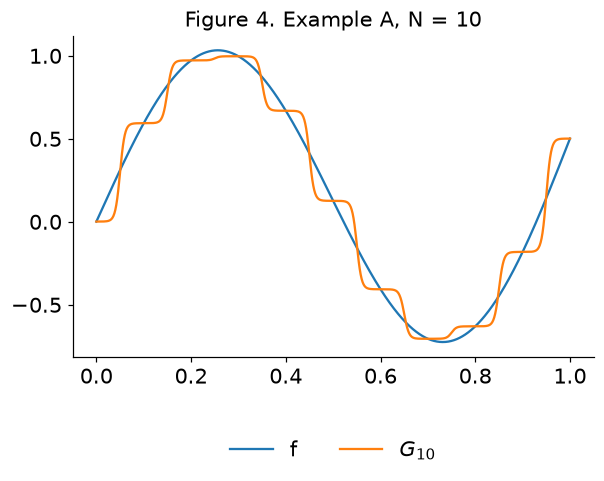

In [20]:
# c.8
def f(x):
    return np.sin(2 * np.pi * x) + x**2 / 2

def stair(fun, n, lam):
    k = np.arange(1, n + 1)
    jumps = fun(k / n) - fun((k - 1) / n)
    centres = (k - 1 / 2) / n
    return lambda x: fun(0.) + logistic_sigmoid(lam * (np.asarray(x)[..., None] - centres)) @ jumps

x8 = np.linspace(0, 1, 1001)
fig, ax = plt.subplots(figsize=(wFull, 0.62 * wFull))
ax.plot(x8, f(x8), label="f")
ax.plot(x8, stair(f, 10, 200)(x8), label="$G_{10}$")
ax.set(title="Figure 4. Example A, N = 10")
legend_below(ax, ncol=2)
plt.show()

Measure the uniform (sup-norm) error on a fine grid, with steepness λ = 20N:

*Table 2. Sup-norm error of ${G}_{N}$ for example A: it halves each time N doubles.*

In [21]:
# c.9
xGrid = np.linspace(0., 1., 2001)   # step 0.0005
def supErr(fun, n):
    return np.max(np.abs(fun(xGrid) - stair(fun, n, 20 * n)(xGrid)))

table([["N", "max error"]] + [[n, f"{supErr(f, n):.3g}"] for n in [5, 10, 20, 40, 80]], "Table 2")

N,max error
5,0.442
10,0.22
20,0.11
40,0.0551
80,0.0276


The error goes 0.44, 0.22, 0.11, 0.055, 0.028: it is O(1/N).

### Examples B–E: harder functions, and one the theorem does not cover

The same construction applied to four more functions on [0, 1]:

- B: |x - 1/2|, continuous but with a kink (no derivative) at 1/2.
- C: √x, continuous, but its slope is infinite at 0.
- D: exp(-200 (x - 1/2)²), smooth but a narrow bump about 0.1 wide.
- E: the step H(x - 0.3) (`unit_step` in c.0), which jumps at 0.3 and is not continuous. Cybenko's theorem says nothing about uniform approximation of such a function.

*Figure 5. Examples B–E (blue) and their staircases ${G}_{10}$ (orange).*

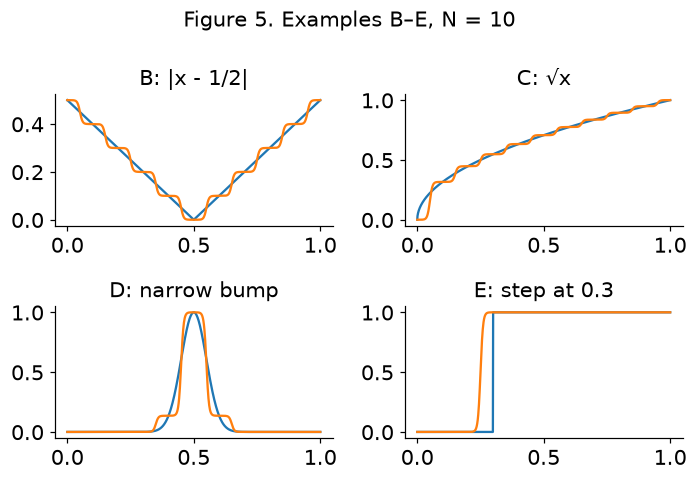

In [22]:
# c.10
examples = {
    "B": lambda x: np.abs(x - 1 / 2),
    "C": lambda x: np.sqrt(x),
    "D": lambda x: np.exp(-200 * (x - 1 / 2)**2),
    "E": lambda x: unit_step(x - 0.3)}
exampleNames = {"A": "sin(2πx) + x²/2", "B": "|x - 1/2|", "C": "√x", "D": "narrow bump", "E": "step at 0.3"}
fig, axs = plt.subplots(2, 2, figsize=(2 * wHalf + 0.6, 2 * 0.75 * wHalf))
for ax, (key, fn) in zip(axs.flat, examples.items()):
    ax.plot(x8, fn(x8))
    ax.plot(x8, stair(fn, 10, 200)(x8))
    ax.set_title(f"{key}: {exampleNames[key]}")
fig.suptitle("Figure 5. Examples B–E, N = 10", fontsize=figFont)
fig.tight_layout()
plt.show()

*Table 3. Sup-norm error of ${G}_{N}$ for the five examples: A sin(2πx) + x²/2, B |x - 1/2|, C √x, D narrow bump, E step at 0.3.*

In [23]:
# c.11
allExamples = {"A": f, **examples}
table([["", "N = 5", "N = 10", "N = 20", "N = 40", "N = 80"]] +
      [[key] + [f"{supErr(fn, n):.2g}" for n in [5, 10, 20, 40, 80]] for key, fn in allExamples.items()],
      "Table 3")

,N = 5,N = 10,N = 20,N = 40,N = 80
A,0.44,0.22,0.11,0.055,0.028
B,0.1,0.03,0.015,0.0076,0.0038
C,0.24,0.17,0.12,0.086,0.061
D,0.86,0.26,0.19,0.092,0.046
E,0.5,1,1,1,1


What a test run showed, and why:

- A and B: the error halves when N doubles. A kink costs nothing, because the staircase only needs the values of f, not its derivative.
- C: the error shrinks only by a factor of about 1/√2 per doubling (0.24, 0.17, 0.12, 0.086, 0.061), so it is O(${N}^{-1/2}$). Near 0, √x changes by √(1/N) over an interval of length 1/N.
- D: the error is large (0.86) until the steps are finer than the bump, then falls like 1/N. A function with fine detail needs many units before the approximation starts to work.
- E: the error never goes to zero; it stays between 0.5 and 1. A jump cannot be followed uniformly by a continuous function, because every finite sum of sigmoids is continuous. In the weaker sense of area between the curves, Theorem 4, the error does go to zero.

The rule behind all five: the error is of the order of the largest change of f over an interval of length 1/N. That quantity is the modulus of continuity ${\omega}_{f}$(1/N), Eq. (12) in Appendix A. It goes to 0 exactly when f is uniformly continuous, and Table 6 computes it for these examples.

## 5. Seeing it work in two dimensions: fitting the outer weights

The target is a smooth function of two variables. First, look at it:

*Figure 6. The target g(x, y) = sin(πx) cos(πy) on [-1, 1]².*

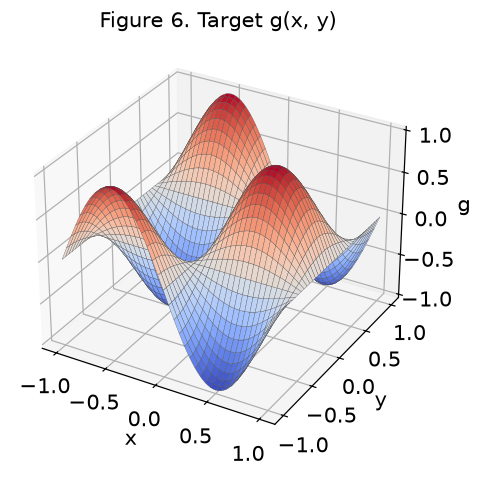

In [24]:
# c.12
def g(x, y):
    return np.sin(np.pi * x) * np.cos(np.pi * y)

gx, gy = np.meshgrid(np.linspace(-1, 1, 81), np.linspace(-1, 1, 81))
fig = plt.figure(figsize=(0.8 * wFull, 0.8 * wFull))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(gx, gy, g(gx, gy), cmap="coolwarm", rstride=2, cstride=2, lw=0.2, edgecolor="0.3")
ax.set(xlabel="x", ylabel="y", zlabel="g", title="Figure 6. Target g(x, y)")
plt.show()

In practice the inner weights ${y}_{j}$, ${\theta}_{j}$ are not placed by hand. A quick experiment: choose them at random, then solve a linear least-squares problem for the outer weights ${\alpha}_{j}$ of Eq. (3). This only finds the best α for random inner weights, so it is weaker than full training, yet the error still falls fast as N grows.

In [25]:
# c.13
rng = np.random.default_rng(3)
trainPts = rng.uniform(-1, 1, (2000, 2))
testPts = rng.uniform(-1, 1, (2000, 2))
def hidden(pts, Yin, th):
    return logistic_sigmoid(pts @ Yin.T + th)

def fit(nh):
    Yr = rng.uniform(-6, 6, (nh, 2))
    th = rng.uniform(-6, 6, nh)
    a = np.linalg.lstsq(hidden(trainPts, Yr, th), g(*trainPts.T), rcond=None)[0]
    return Yr, th, a

*Table 4. Maximum error on 2000 test points, for N random hidden units.*

In [26]:
# c.14
def maxTestErr(m):
    return np.max(np.abs(hidden(testPts, m[0], m[1]) @ m[2] - g(*testPts.T)))

table([["N", "max test error"]] + [[nh, f"{maxTestErr(fit(nh)):.3g}"] for nh in [10, 50, 200]], "Table 4")

N,max test error
10,0.978
50,0.0644
200,0.000168


In a test run the maximum error went from about 1 with N = 10, to under 0.1 with N = 50, to about ${10}^{-4}$ with N = 200.

*Figure 7. Left: the fit by a sum of 100 sigmoids, to compare with Figure 6. Right: the error g - G, on a much smaller vertical scale.*

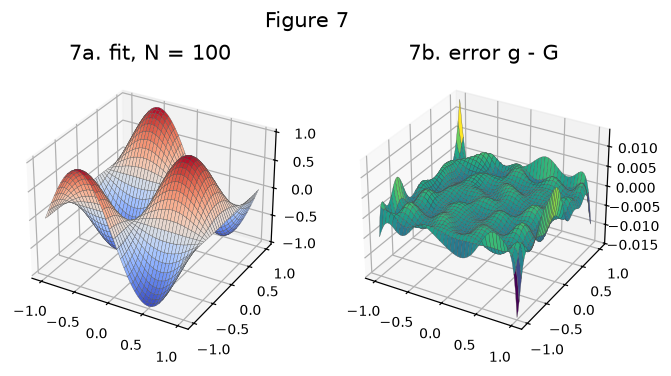

In [27]:
# c.15
m = fit(100)
def G100(x, y):
    pts = np.column_stack([x.ravel(), y.ravel()])
    return (hidden(pts, m[0], m[1]) @ m[2]).reshape(x.shape)

fig = plt.figure(figsize=(2 * wHalf + 1.2, 1.1 * wHalf))
a1 = fig.add_subplot(1, 2, 1, projection="3d")
a1.plot_surface(gx, gy, G100(gx, gy), cmap="coolwarm", rstride=2, cstride=2, lw=0.2, edgecolor="0.3")
a1.set_title("7a. fit, N = 100")
a2 = fig.add_subplot(1, 2, 2, projection="3d")
a2.plot_surface(gx, gy, g(gx, gy) - G100(gx, gy), cmap="viridis", rstride=2, cstride=2, lw=0.2, edgecolor="0.3")
a2.set_title("7b. error g - G")
for a in (a1, a2):
    a.tick_params(labelsize=figFont - 5)
fig.suptitle("Figure 7", fontsize=figFont, y=1.04)
plt.show()

## 6. The original: Kolmogorov's superposition theorem (1957)

### Background: Hilbert's 13th problem

In 1900 Hilbert asked whether the roots of the degree-7 equation x⁷ + a x³ + b x² + c x + 1 = 0, a function of three variables (a, b, c), can be written as a composition of functions of only two variables. He conjectured that they cannot. The continuous version of the question was settled in the opposite direction:

- 1956: Kolmogorov shows that every continuous function of several variables is a finite superposition of continuous functions of three variables.
- 1957: Arnold, then 19 and Kolmogorov's student, reduces this to functions of two variables, answering Hilbert's question for continuous functions.
- 1957: Kolmogorov goes all the way down: functions of one variable plus addition are enough.
- The algebraic version of Hilbert's problem is still open.

### The theorem

**Theorem 5 (Kolmogorov 1957).** Every continuous (Appendix A) $f : {[ 0 , 1 ]}^{n} \to \mathbb{R}$, n ≥ 2, can be written exactly as

$$
f ( {x}_{1} , \ldots , {x}_{n} ) = {\sum}_{q = 0}^{2 n} {\Phi}_{q} ( {\sum}_{p = 1}^{n} {\psi}_{p , q} ( {x}_{p} ) ) \tag{8}
$$

- The inner functions ${\psi}_{p,q}$ of Eq. (8) are continuous and increasing, and universal: they depend only on n, not on f.
- The outer functions ${\Phi}_{q}$ are continuous and depend on f.
- The number of terms is fixed at 2n + 1, and the representation is exact, not approximate.
- Later refinements by Lorentz and Sprecher reduce the outer functions to a single function, and the inner functions to scaled and shifted copies of one function.

The message: the only genuinely multivariate function you ever need is addition.

#### Elementary examples of the idea

Multiplication, the simplest nonlinear function of two variables, is a sum of one-variable functions of sums:

In [28]:
# c.16
x, y = sp.symbols("x y", real=True)
print(sp.simplify(((x + y)**2 - (x - y)**2) / 4 - x * y) == 0)
xp, yp = sp.symbols("x y", positive=True)
print(sp.simplify(sp.exp(sp.log(xp) + sp.log(yp)) - xp * yp) == 0)

True
True


The second identity already has the shape of Eq. (8): inner functions ψ = Log on each variable, add them, then one outer function Φ = Exp.

### As a network

Hecht-Nielsen (1987) pointed out that Eq. (8) is a feedforward network: one layer computes the inner functions, the next adds them and applies the outer functions, and the output adds those. For n = 2 there are 2n + 1 = 5 branches (Figure 8).

*Figure 8. Eq. (8) as a network for n = 2. The arrows mean something slightly different from those in Figure 3: they carry a value without multiplying it by a weight. Each ${\psi}_{pq}$ node applies its own one-variable function to its input, each ${\Phi}_{q}$ node adds what arrives and then applies ${\Phi}_{q}$, and f adds the five branches. In Figure 3 every node applies the same σ and all the flexibility sits in the weights on the arrows; here there are no weights and all the flexibility sits in the node functions.*

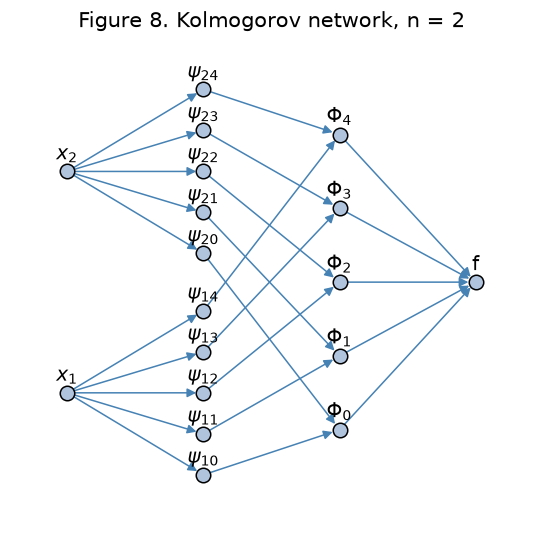

In [29]:
# c.17
K = nx.DiGraph()
for p in (1, 2):
    for q in range(5):
        K.add_edge(f"x{p}", f"ψ{p}{q}")
        K.add_edge(f"ψ{p}{q}", f"Φ{q}")
for q in range(5):
    K.add_edge(f"Φ{q}", "f")
layer = {v: 0 if v.startswith("x") else 1 if v.startswith("ψ") else 2 if v.startswith("Φ") else 3 for v in K}
nx.set_node_attributes(K, layer, "layer")
# layers from left to right, nodes in index order within each layer
# x2 above its five ψ nodes, x1 below; Φ4 at the top (as in the Wolfram layout)
pos = {"f": (3, 0)}
for p in (1, 2):
    pos[f"x{p}"] = (0, (p - 1.5) * 5.4)
    for q in range(5):
        pos[f"ψ{p}{q}"] = (1, (p - 1.5) * 5.4 + (q - 2) * 1.0)
for q in range(5):
    pos[f"Φ{q}"] = (2, (q - 2) * 1.8)
tex = {v: f"$x_{v[1]}$" if v[0] == "x" else f"$\\psi_{{{v[1:]}}}$" if v[0] == "ψ"
       else f"$\\Phi_{v[1]}$" if v[0] == "Φ" else "f" for v in K}
fig, ax = plt.subplots(figsize=(wFull, 0.95 * wFull))
nx.draw_networkx_nodes(K, pos, node_size=90, node_color="lightsteelblue", edgecolors="black", ax=ax)
nx.draw_networkx_edges(K, pos, arrowsize=12, node_size=90, ax=ax, edge_color="steelblue")
nx.draw_networkx_labels(K, {v: (a, b + 0.42) for v, (a, b) in pos.items()}, tex, font_size=figFont - 1, ax=ax)
ax.set_title("Figure 8. Kolmogorov network, n = 2", fontsize=figFont)
ax.margins(0.08)
ax.axis("off")
plt.show()

The catch is that the inner functions are pathological. They are continuous but extremely rough, like the Weierstrass and Cantor functions of Figure 9 (Appendix A), with fractal-like graphs built from devil's-staircase constructions, and the outer functions inherit that roughness. Results going back to Vitushkin show that, in general, the representation is impossible with smooth inner functions.

## 7. Connecting the two theorems

Write Cybenko's sum, Eq. (3), with the inner product spelled out, next to Kolmogorov's formula, Eq. (8):

$$
\begin{gathered}G ( x ) = {\sum}_{j = 1}^{N} {\alpha}_{j} \  \sigma ( {\sum}_{p = 1}^{n} {y}_{j p} {x}_{p} + {\theta}_{j} ) \quad  \text{(Cybenko)} \\ f ( x ) = {\sum}_{q = 0}^{2 n} {\Phi}_{q} ( {\sum}_{p = 1}^{n} {\psi}_{p , q} ( {x}_{p} ) ) \quad  \text{(Kolmogorov)}\end{gathered} \tag{9}
$$

The two sides of Eq. (9) match term by term. Cybenko's network is a Kolmogorov representation in which the inner functions are linear, ${\psi}_{p , j} ( {x}_{p} ) = {y}_{j p} {x}_{p}$, and every outer function is a scaled and shifted copy of the same S-shape, ${\Phi}_{j} ( s ) = {\alpha}_{j} \sigma ( s + {\theta}_{j} )$. In the pictures, Figure 8 becomes Figure 3 when you move the flexibility off the node functions and onto weights on the arrows. Trading Kolmogorov's wild, special-purpose functions for one simple, smooth, fixed one costs two things: the representation is no longer exact, and the number of terms is no longer 2n + 1 but N(ε), which may be enormous.

*Table 5. The two theorems compared.*

|  | Kolmogorov (1957), Eq. (8) | Cybenko (1989), Eq. (3) |
|---|---|---|
| result | exact representation | approximation to any ε |
| number of terms | 2n + 1, fixed | N, grows as ε → 0 |
| inner functions | special, very rough, independent of f | linear: y·x + θ |
| outer functions | depend on f, rough | one fixed smooth σ, scaled by α<sub>j</sub> |
| arrows in the diagram | carry values, no weights (Figure 8) | carry values times weights (Figure 3) |
| network reading | two hidden layers (Hecht-Nielsen) | one hidden layer |
| proof | explicit construction | existence (Hahn–Banach, Riesz) |


Cybenko makes the contrast himself. He notes Kolmogorov's exact representation, but points out that it uses different nonlinear functions for different purposes, while he wants one fixed univariate function, and that asking for exact representation is asking too much.

### The relevance debate

- Hecht-Nielsen (1987) proposed Kolmogorov's theorem as a foundation for neural networks (the "Kolmogorov mapping neural network existence theorem").
- Girosi and Poggio (1989) answered with "Kolmogorov's theorem is irrelevant": the inner functions are far too rough to learn or to generalize from, and the outer ones depend on f in an uncontrolled way.
- Kůrková (1991, "Kolmogorov's theorem is relevant"; 1992) replied that you do not need the exact theorem: approximating its ingredients with staircases of sigmoids gives universal approximation with two hidden layers, together with estimates of how many hidden units are needed.
- Schmidt-Hieber (2021) revisited the theorem and argued that it is more naturally read as a deep network, which deep ReLU networks can approximate well.

### After Cybenko: the S-shape is sufficient but not necessary

- **Theorem 6 (Hornik, Stinchcombe and White 1989).** If ψ is any squashing function (nondecreasing, with limits 0 and 1), one-hidden-layer networks with activation ψ approximate every continuous function on ${\mathbb{R}}^{n}$ uniformly on compact sets, and every Borel measurable function in measure. The proof uses the Stone–Weierstrass theorem.
- **Theorem 7 (Hornik 1991).** If the activation is bounded and nonconstant, one-hidden-layer networks are dense in ${L}^{p}$(μ) for every finite measure μ on ${\mathbb{R}}^{n}$ and 1 ≤ p < ∞. If it is also continuous, they approximate every continuous function uniformly on compact sets. The S-shape itself is not needed.
- **Theorem 8 (Leshno, Lin, Pinkus and Schocken 1993).** Let the activation σ be locally bounded and piecewise continuous. One-hidden-layer networks approximate every continuous function on ${\mathbb{R}}^{n}$ uniformly on compact sets if and only if σ is not a polynomial. This covers ReLU, which is not S-shaped at all.
- Barron (1993) gave approximation rates for sigmoidal networks that, for a suitable class of functions, do not grow exponentially with the dimension.
- Liu et al. (2024), "KAN: Kolmogorov–Arnold Networks", returned to the Kolmogorov form of Figure 8: learnable one-variable functions (splines) on the edges and plain addition at the nodes.

So why S-shapes historically? They are the smallest change from the biological threshold neuron that makes gradient training possible, and they were the setting in which universality was first proved. Their limits at ±∞, Eq. (1), are exactly what turns a sum of them into a staircase that can follow any continuous function.

## 8. Exercises

- Repeat the staircase experiment of section 4 (Table 3) with the arctan and algebraic sigmoids. Why do you need a larger λ for the same error?
- Try a non-monotone function such as σ(t) + sin(t) exp(-t²). Is it sigmoidal in the sense of Eq. (1), and does the staircase still converge?
- Try the least-squares fit of section 5 (Table 4) with σ(t) = t², a polynomial. The error stops improving. Which of Theorems 1–8 explains this?
- Write x y z as a superposition in the form of Eq. (8), using one-variable functions and addition, valid for positive x, y, z.
- Show that one step of BasicRecurrentLayer, tanh(W x + U h + b), is a Cybenko-type sum when you take (x, h) as the input. Draw its graph in the style of Figure 3. Which arrow would you add to make it recurrent?
- Use Eq. (5) to write ∂G/∂${\alpha}_{j}$ and ∂G/∂${y}_{ji}$, and check both against SymPy's `diff` as in c.7.
- Run the staircase of section 4 on x sin(1/x) (with value 0 at 0) and on the Cantor staircase of Figure 9. Predict the rate of convergence from the modulus of continuity, Eq. (12), before you measure it.

## Appendix A. Continuous functions

Both theorems are about continuous functions: Cybenko's approximates every function in C(${I}_{n}$), and Kolmogorov's represents every continuous function exactly. This appendix collects what continuity means, how it differs from uniform continuity, and some examples and counterexamples, several of which appear in the main text.

### A.1 Definition

In everyday terms: f is continuous at a point a if a small change in the input near a produces only a small change in the output. On an interval, the graph of a continuous function can be drawn without lifting the pen. In mathematical terms, f: D → ℝ is continuous at a ∈ D if

$$
\begin{gathered}\forall \varepsilon > 0 \  \exists \delta > 0 \  \forall x \in D : \\ \quad  \lvert x - a \rvert < \delta \quad  \implies \quad  \lvert f ( x ) - f ( a ) \rvert < \varepsilon\end{gathered} \tag{10}
$$

- f is continuous on D if Eq. (10) holds at every point of D.
- Equivalent forms: ${\lim }_{x\to a}$ f(x) = f(a); or, for every sequence ${x}_{k}$ → a, f(${x}_{k}$) → f(a).
- For functions of several variables, replace |x - a| by the Euclidean distance ‖x - a‖. This is the sense used for C(${I}_{n}$).
- Sums, products, quotients (where defined) and compositions of continuous functions are continuous. That is why every network in Eq. (3), (4) and (7) with a continuous σ is a continuous function.

### A.2 Uniform continuity and the modulus of continuity

In Eq. (10), δ may depend on the point a. If one δ works for all points at once, f is uniformly continuous:

$$
\begin{gathered}\forall \varepsilon > 0 \  \exists \delta > 0 \  \forall x , {x}^{\prime} \in D : \\ \quad  \lvert x - {x}^{\prime} \rvert < \delta \quad  \implies \quad  \lvert f ( x ) - f ( {x}^{\prime} ) \rvert < \varepsilon\end{gathered} \tag{11}
$$

The modulus of continuity measures the largest change of f over distances up to δ:

$$
\begin{gathered}{\omega}_{f} ( \delta ) = \sup _{\lvert x - {x}^{\prime} \rvert \le \delta} \lvert f ( x ) - f ( {x}^{\prime} ) \rvert \\ f \  \text{uniformly continuous} \quad  \iff \quad  {\omega}_{f} ( \delta ) \to 0 \  \text{as} \  \delta \to 0\end{gathered} \tag{12}
$$

- **Theorem 9 (Heine–Cantor).** A continuous function on a closed, bounded set, such as [0, 1] or the cube ${I}_{n}$, is uniformly continuous.
- **Theorem 10 (extreme value theorem).** A continuous function on a closed, bounded set attains its maximum and minimum. So the sup norm ‖f‖ = max |f| is finite, and C(${I}_{n}$) with this norm is the space in Theorems 1 and 2.
- Why it matters here: the staircase error in section 4 is of the order of ${\omega}_{f}$(1/N). It goes to 0 for every continuous f on [0, 1] because of Theorem 9, and it does not go to 0 for the jump in example E.

*Table 6. The modulus of continuity ${\omega}_{f}$(δ) of the section 4 examples, computed on a grid. Compare its decay with the error columns of Table 3. Rows A–E as in Table 3.*

In [30]:
# c.18
def omega(fun, d):
    xs = np.arange(0., 1. - d + 1e-12, d / 50)
    hs = np.linspace(0., d, 11)
    return np.max(np.abs(fun(xs[:, None] + hs) - fun(xs)[:, None]))

table([["", "δ = 1/5", "δ = 1/10", "δ = 1/20", "δ = 1/40", "δ = 1/80"]] +
      [[key] + [f"{omega(fn, 1. / n):.2g}" for n in [5, 10, 20, 40, 80]] for key, fn in allExamples.items()],
      "Table 6")

,δ = 1/5,δ = 1/10,δ = 1/20,δ = 1/40,δ = 1/80
A,1.1,0.68,0.36,0.18,0.091
B,0.2,0.1,0.05,0.025,0.013
C,0.45,0.32,0.22,0.16,0.11
D,1,0.89,0.56,0.3,0.15
E,1,1,1,1,1


For √x, ω(δ) = √δ, which explains the O(${N}^{-1/2}$) rate of example C. For the step, ω(δ) = 1 for every δ > 0, which explains why example E never converges. (c.18 uses allExamples from c.11, so run section 4 first.)

### A.3 Examples of continuous functions

- Polynomials, exp, sin, cos, and all the sigmoids of Figure 1 except the step.
- |x|: continuous everywhere, not differentiable at 0. Continuity is much weaker than smoothness.
- √x on [0, 1]: continuous, and uniformly so, but not Lipschitz, because its slope is unbounded near 0.
- x sin(1/x), with value 0 at 0: continuous at 0, because |x sin(1/x)| ≤ |x|, but it oscillates infinitely often near 0 and is not differentiable there.
- The Weierstrass function W(x) = ∑ ${a}^{k}$ cos(${b}^{k}$ π x), with 0 < a < 1, b an odd integer, and a b > 1 + 3π/2: continuous everywhere and differentiable nowhere. Figure 9 plots a partial sum.
- The Cantor staircase (devil's staircase): continuous and increasing from 0 to 1, yet flat on intervals of total length 1. Kolmogorov's inner functions are built in this spirit.

SymPy can test continuity with `continuous_domain`; c.19 wraps it as `functionContinuous`, with a test of the one-sided limits for steps, which `continuous_domain` cannot handle. Limits show what happens at the critical point:

In [31]:
# c.19
from sympy.calculus.util import continuous_domain

def functionContinuous(expr, x, domain=sp.S.Reals):
    """True if expr is continuous at every point of domain (like FunctionContinuous)."""
    steps = list(expr.atoms(sp.Heaviside))
    if steps:   # continuous_domain cannot handle steps: compare one-sided limits at each jump
        for H in steps:
            for a in sp.solveset(H.args[0], x, domain):
                if sp.limit(expr, x, a, "-") != sp.limit(expr, x, a, "+"):
                    return False
        expr = expr.subs({H: 1 for H in steps})
    return domain.is_subset(continuous_domain(expr, x, domain))

x = sp.symbols("x", real=True)
{"x sin(1/x) away from 0": functionContinuous(x * sp.sin(1 / x), x, sp.S.Reals - sp.FiniteSet(0)),
 "√x on [0,1]": functionContinuous(sp.sqrt(x), x, sp.Interval(0, 1)),
 "|x|": functionContinuous(sp.Abs(x), x),
 "1/x on (0,1]": functionContinuous(1 / x, x, sp.Interval.Lopen(0, 1)),
 "step on ℝ": functionContinuous(sp.Heaviside(x), x)}

{'x sin(1/x) away from 0': True,
 '√x on [0,1]': True,
 '|x|': True,
 '1/x on (0,1]': True,
 'step on ℝ': False}

In [32]:
# c.20
{"x sin(1/x), x → 0": sp.limit(x * sp.sin(1 / x), x, 0),
 "sin(1/x), x → 0": sp.limit(sp.sin(1 / x), x, 0),
 "step, from the left": sp.limit(sp.Heaviside(x), x, 0, "-"),
 "step, from the right": sp.limit(sp.Heaviside(x), x, 0, "+")}

{'x sin(1/x), x → 0': 0,
 'sin(1/x), x → 0': AccumBounds(-1, 1),
 'step, from the left': 0,
 'step, from the right': 1}

The limit of x sin(1/x) is 0, which matches its value, so it is continuous at 0. sin(1/x) has no limit (SymPy returns AccumBounds(-1, 1): it keeps visiting every value between -1 and 1; Wolfram Language returns Indeterminate), and the step has different one-sided limits, 0 and 1, so neither can be made continuous at 0.

*Figure 9. Continuous functions. 9a and 9b are tame; 9c, 9d and 9e are continuous but strange.*

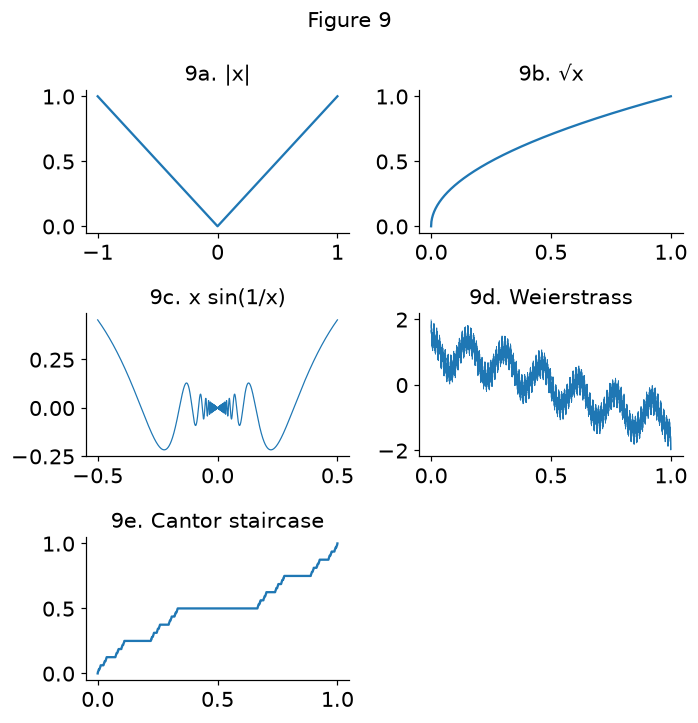

In [33]:
# c.21
# partial sum of the Weierstrass function, a = 1/2, b = 13
def weierstrass(x, m=6):
    return sum(0.5**k * np.cos(13**k * np.pi * x) for k in range(m + 1))

def cantorStaircase(x, digits=40):
    """Cantor function from the ternary digits of x: a digit 1 ends the expansion."""
    x = np.clip(np.asarray(x, float), 0, 1)
    out = np.zeros_like(x)
    alive = np.ones_like(x, bool)
    r = x.copy()
    for k in range(1, digits + 1):
        r = 3 * r
        d = np.minimum(np.floor(r), 2)
        r -= d
        out += np.where(alive & (d >= 1), 0.5**k, 0.0)
        alive &= d != 1
    return np.where(x >= 1, 1.0, out)

fig, axs = plt.subplots(3, 2, figsize=(2 * wHalf + 0.6, 3 * 0.75 * wHalf))
xa = np.linspace(-1, 1, 801); axs[0, 0].plot(xa, np.abs(xa)); axs[0, 0].set_title("9a. |x|")
xb = np.linspace(0, 1, 801); axs[0, 1].plot(xb, np.sqrt(xb)); axs[0, 1].set_title("9b. √x")
xc = np.linspace(-0.5, 0.5, 20001); xc = xc[xc != 0]
axs[1, 0].plot(xc, xc * np.sin(1 / xc), lw=0.8); axs[1, 0].set_title("9c. x sin(1/x)")
xd = np.linspace(0, 1, 30001); axs[1, 1].plot(xd, weierstrass(xd), lw=0.5); axs[1, 1].set_title("9d. Weierstrass")
axs[2, 0].plot(xb, cantorStaircase(np.linspace(0, 1, 801))); axs[2, 0].set_title("9e. Cantor staircase")
axs[2, 1].axis("off")
fig.suptitle("Figure 9", fontsize=figFont)
fig.tight_layout()
plt.show()

### A.4 Counterexamples

- The Heaviside step: a jump at 0. Its left limit is 0 and its right limit is 1, so no value at 0 makes it continuous. Example E of section 4 shows the consequence for approximation.
- sin(1/x), with any value at 0: it oscillates between -1 and 1 infinitely often near 0, so it has no limit there.
- The Dirichlet function, 1 on the rationals and 0 on the irrationals: discontinuous at every point. It cannot be meaningfully plotted.
- Thomae's function, 1/q at x = p/q in lowest terms and 0 at irrationals: discontinuous at every rational and continuous at every irrational.
- 1/x on (0, 1]: continuous at every point of its domain, but not uniformly continuous and not bounded. The domain is not closed, so Theorem 9 does not apply. This is why both theorems work on the closed cube ${[ 0 , 1 ]}^{n}$.
- x² on all of ℝ: continuous but not uniformly continuous, because the domain is unbounded.

*Figure 10. 10a–10c are not continuous. 10d is continuous but not uniformly continuous.*

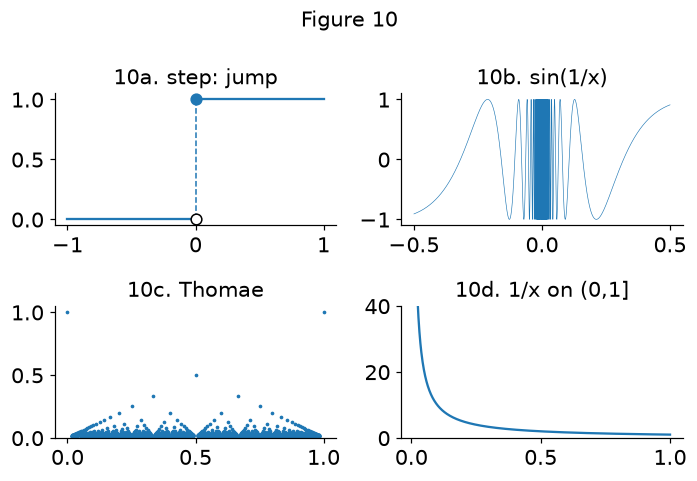

In [34]:
# c.22
fig, axs = plt.subplots(2, 2, figsize=(2 * wHalf + 0.6, 2 * 0.75 * wHalf))
ax = axs[0, 0]
ax.plot([-1, 0], [0, 0], color="C0"); ax.plot([0, 1], [1, 1], color="C0")
ax.plot([0, 0], [0, 1], "--", color="C0", lw=1)
ax.plot(0, 1, "o", color="C0", ms=7)
ax.plot(0, 0, "o", mfc="white", mec="black", ms=7)
ax.set_title("10a. step: jump")
xs10 = np.linspace(-0.5, 0.5, 40001); xs10 = xs10[xs10 != 0]
axs[0, 1].plot(xs10, np.sin(1 / xs10), lw=0.4); axs[0, 1].set_title("10b. sin(1/x)")
thomae = {p / q: 1 / q for q in range(60, 0, -1) for p in range(q + 1)}
axs[1, 0].scatter(list(thomae), list(thomae.values()), s=2)
axs[1, 0].set(ylim=(0, 1.05), title="10c. Thomae")
xr = np.linspace(0.01, 1, 800); axs[1, 1].plot(xr, 1 / xr)
axs[1, 1].set(ylim=(0, 40), title="10d. 1/x on (0,1]")
fig.suptitle("Figure 10", fontsize=figFont)
fig.tight_layout()
plt.show()

*Table 7. The examples and counterexamples at a glance.*

| function | continuous? | uniformly continuous? | differentiable? |
|---|---|---|---|
| \|x - 1/2\| on [0,1] | yes | yes | except at 1/2 |
| √x on [0,1] | yes | yes | except at 0 |
| x sin(1/x), 0 at 0 | yes | yes on [-1,1] | except at 0 |
| Weierstrass W | yes | yes | nowhere |
| Cantor staircase | yes | yes | slope 0 almost everywhere |
| step at 0.3 | no (jump) | no | except at 0.3 |
| sin(1/x) | no (at 0) | no | except at 0 |
| 1/x on (0,1] | yes | no | yes |
| Dirichlet | nowhere | no | nowhere |
| Thomae | at irrationals only | no | nowhere |


## References

References for section 0 are listed in 0.8.

### Sections 1–7

- G. Cybenko, Approximation by superpositions of a sigmoidal function, Math. Control Signals Systems 2 (1989) 303–314. doi:10.1007/BF02551274
- A. N. Kolmogorov, On the representation of continuous functions of many variables by superposition of continuous functions of one variable and addition, Dokl. Akad. Nauk SSSR 114 (1957) 953–956.
- V. I. Arnold, On functions of three variables, Dokl. Akad. Nauk SSSR 114 (1957) 679–681.
- R. Hecht-Nielsen, Kolmogorov's mapping neural network existence theorem, Proc. IEEE First Int. Conf. on Neural Networks, III (1987) 11–14.
- F. Girosi, T. Poggio, Representation properties of networks: Kolmogorov's theorem is irrelevant, Neural Computation 1 (1989) 465–469. doi:10.1162/neco.1989.1.4.465
- V. Kůrková, Kolmogorov's theorem is relevant, Neural Computation 3 (1991) 617–622. doi:10.1162/neco.1991.3.4.617
- V. Kůrková, Kolmogorov's theorem and multilayer neural networks, Neural Networks 5 (1992) 501–506. doi:10.1016/0893-6080(92)90012-8
- K. Hornik, M. Stinchcombe, H. White, Multilayer feedforward networks are universal approximators, Neural Networks 2 (1989) 359–366. doi:10.1016/0893-6080(89)90020-8
- K. Hornik, Approximation capabilities of multilayer feedforward networks, Neural Networks 4 (1991) 251–257.
- M. Leshno, V. Ya. Lin, A. Pinkus, S. Schocken, Multilayer feedforward networks with a nonpolynomial activation function can approximate any function, Neural Networks 6 (1993) 861–867. doi:10.1016/S0893-6080(05)80131-5
- A. R. Barron, Universal approximation bounds for superpositions of a sigmoidal function, IEEE Trans. Information Theory 39 (1993) 930–945.
- J. Schmidt-Hieber, The Kolmogorov–Arnold representation theorem revisited, Neural Networks 137 (2021) 119–126.
- Z. Liu et al., KAN: Kolmogorov–Arnold Networks, arXiv:2404.19756 (2024).

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>